# Cone-beam micro-CT

A laboratory micro-CT scanner turns the sample on a stage between a point-like X-ray source and a flat-panel detector, so every projection is a cone of rays. This tutorial reconstructs a scan of a plastic tube packed with glass beads from the SophiaBeads Dataset Project, made on a Nikon XT H 225 at the University of Manchester. It reads the scanner's geometry file, finds the centre of rotation from the data, and reconstructs with FDK (filtered back projection for cone beams) and with OS-SART.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("CT/SophiaBeads-256")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("CT/SophiaBeads-256")

CT/SophiaBeads-256: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.metadata.CT import CTConeBeamFlatPanelProjMeta
from pytomography.projectors.CT import CTConeBeamFlatPanelSystemMatrix
from pytomography.algorithms import FilteredBackProjection, SART

In [3]:
# Memory: the FDK and OS-SART reconstructions below print their estimates before they run (estimate_memory): their
# peak RAM and GPU memory, what they are made of, and what to change to use less. The tutorial peaks at about 13 GB of
# RAM and 7 GB of GPU memory (measured on Windows). Its reconstructions do not split their work by the memory budget,
# so a lower RAM_GB changes nothing here: with binning = 4 it needs about 13 GB whatever RAM_GB is. To use less RAM and
# GPU memory, set binning = 8 below (a grid with eight times fewer voxels), or use fewer OS-SART subsets (each keeps an
# image on the GPU).
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The scan

Nikon scanners describe a scan in an `.xtekct` file, in INI format, list the stage angle of every projection in an `.ang` file, and store each projection as a TIFF. `io.CT.read_nikon` reads them all. The geometry needs three numbers from the `.xtekct` file: the distances from the source to the rotation axis and to the detector, and the detector's pixel size. Their ratio is the magnification, so a detector pixel of 0.2 mm sees 0.016 mm of the sample.

In [4]:
folder = DATA / 'CT' / 'SophiaBeads-256' / 'SophiaBeads_256_averaged'
binning = 4  # 8 gives a grid with eight times fewer voxels, if your GPU has less than 8 GB of memory

t0 = time.time()
proj, object_meta, proj_meta = io.CT.read_nikon(folder, binning=binning)
proj = proj.to(pytomography.device)
magnification = proj_meta.DSD / proj_meta.DSO
step = float(torch.diff(proj_meta.angles).abs().mean())   # degrees
print(f"{len(proj_meta.angles)} projections {step:.2f}° apart, binned to {proj.shape[1]} × {proj.shape[2]} pixels of "
      f"{proj_meta.dr[0]:.1f} mm, magnification {magnification:.2f}")
print(f"projections {tuple(proj.shape)} read in {time.time() - t0:.0f} s")

255 projections 1.41° apart, binned to 500 × 500 pixels of 0.8 mm, magnification 12.49
projections (255, 500, 500) read in 6 s


## 2. Projections

Each projection is a TIFF of detector readings $I$. The line integral of attenuation along each ray is $-\ln(I / I_0)$, with $I_0$ the white level (the reading with nothing in the beam, `WhiteLevel` in the `.xtekct` file). `binning=4` averages 4 × 4 blocks of pixels before taking the logarithm, like binning on the detector, which gives 500 × 500 projections and a grid that fits on most GPUs. The folder also holds a 256th image that the angle file does not list; the reader leaves it out.

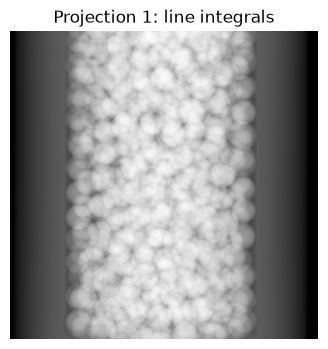

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(proj[0].T.cpu(), cmap='Greys_r')
ax.set_title('Projection 1: line integrals')
ax.axis('off')
plt.show()

## 3. Geometry

`read_nikon` describes the geometry with `CTConeBeamFlatPanelProjMeta`: the source at `beam_radius` from the rotation axis and the detector centre at `detector_radius` on the other side, for each angle. Here the stage turns the sample, so in the sample's frame the source and detector turn the other way: the reader negates the angles of the `.ang` file. `COR` is how far the rotation axis lies from the central ray, in mm at the axis; the files do not give it (`cor` of `read_nikon`, 0 by default), so section 4 finds it from the data.

The detector's rows cover 32 mm at the axis, so the reader's grid, a cube of 500 voxels of $0.2 \times 4 / M = 0.064$ mm, holds everything the rays pass through near the axis.

In [6]:
n = object_meta.shape[0]  # 500 voxels across


def system_matrix_for(cor, n_slices):
    """read_nikon's geometry with the rotation axis cor mm from the central ray, on n_slices central slices of its grid"""
    proj_meta_cor = CTConeBeamFlatPanelProjMeta(
        proj_meta.angles, proj_meta.z_locations,
        detector_radius=proj_meta.detector_radius, beam_radius=proj_meta.beam_radius,
        shape=proj_meta.shape, dr=proj_meta.dr, COR=cor)
    return CTConeBeamFlatPanelSystemMatrix(object_meta.with_grid(shape=(n, n, n_slices)), proj_meta_cor)

## 4. The centre of rotation

The geometry file gives no offset for the rotation axis, but a scanner's axis is rarely exactly on its central ray. An offset of a fraction of a millimetre doubles every edge, so it can be found from the data: reconstruct a few central slices for a range of offsets, and keep the one with the sharpest image, measured as the mean squared difference between neighbouring voxels. Each trial takes about a second.

In [7]:
def sharpness(image):
    s = image[:, :, image.shape[2] // 2]
    return float(((s[1:] - s[:-1]) ** 2).mean() + ((s[:, 1:] - s[:, :-1]) ** 2).mean())


cors = np.round(np.arange(0.0, 0.5, 0.02), 2)  # mm
trials = {cor: FilteredBackProjection(proj, system_matrix_for(cor, 4), filter='ram-lak')() for cor in cors}
scores = [sharpness(trials[cor]) for cor in cors]
best_cor = float(cors[int(np.argmax(scores))])
print(f"sharpest at COR = {best_cor} mm")

sharpest at COR = 0.24 mm


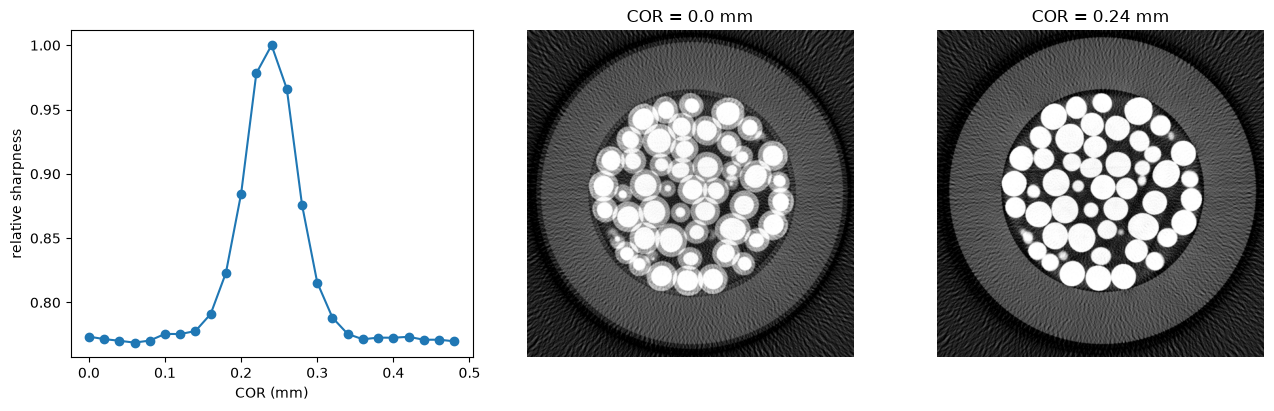

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].plot(cors, np.array(scores) / max(scores), 'o-')
axes[0].set_xlabel('COR (mm)'); axes[0].set_ylabel('relative sharpness')
vmax = float(trials[best_cor].max()) * 0.8
for ax, cor in zip(axes[1:], [0.0, best_cor]):
    ax.imshow(trials[cor][:, :, 2].T.cpu(), cmap='Greys_r', vmin=0, vmax=vmax)
    ax.set_title(f'COR = {cor} mm'); ax.axis('off')
plt.show()

## 5. FDK

FDK weights each projection for the cone angle, filters it row by row with a ramp filter, and back projects it with a distance weight. `FilteredBackProjection` does it for the cone-beam system matrix; `filter='ram-lak'` is the plain ramp, the sharpest window.

In [9]:
system_matrix = system_matrix_for(best_cor, n)
fdk = FilteredBackProjection(proj, system_matrix, filter='ram-lak')
print(fdk.estimate_memory())  # its peak RAM and GPU memory, before it runs
t0 = time.time()
recon_fdk = fdk()
print(f"FDK: {time.time() - t0:.1f} s")

Filtered back projection (CTConeBeamFlatPanelSystemMatrix)
Peak ~ 9.8 GB RAM, 5.5 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 1.5 GB GPU (projections 0.3 GPU, image 1.0 GPU, distance weights of every view 0.3 GPU)
  projector chunks: 0.00 GB RAM, 2.0 GB GPU (one view: back projection, rays, distance weight 2.0 GPU)
  Python, CUDA, allocator: 4.3 GB RAM, 1.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.3 GPU, memory the allocators keep (Windows) 1.2 RAM)
(plus whatever else your script keeps)


FDK: 10.8 s


## 6. OS-SART

OS-SART updates the image from one subset of the projections at a time, to reduce the difference between the measured line integrals and those of the image. Started from the FDK image, three passes through five subsets are enough here; started from a uniform image it needs many more.

In [10]:
# OS-SART keeps one H_m^T 1 image per subset (on the GPU), so here fewer subsets take less memory
print(system_matrix.estimate_memory(n_subsets=5, held={'projections': proj}))
t0 = time.time()
recon_sart = SART(system_matrix, proj, object_initial=recon_fdk.clamp(min=0))(n_iters=3, n_subsets=5)
print(f"OS-SART 3 × 5: {time.time() - t0:.1f} s")

CTConeBeamFlatPanelSystemMatrix: 5 subsets, memory budget 25 GB
Peak ~ 13.9 GB RAM, 8.8 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 3.3 GB GPU (image 0.5 GPU, H_m^T 1 of 5 subsets 2.5 GPU, projections 0.3 GPU)
  one subset at a time: 0.00 GB RAM, 1.7 GB GPU (projections of a subset: measured, predicted, of ones, ratio 0.2 GPU, images of an update 1.5 GPU)
  projector chunks: 0.00 GB RAM, 1.0 GB GPU (one view: rays and the padded image 1.0 GPU)
  Python, CUDA, allocator: 5.1 GB RAM, 2.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 2.1 GPU, memory the allocators keep (Windows) 2.1 RAM)
To use less: 2 subsets ~ 11.9 GB RAM, 7.2 GB GPU
(plus whatever else your script keeps)


OS-SART 3 × 5: 15.4 s


## 7. Comparison

Both images show the same beads, with the same edges. Away from the beads they differ: FDK's ramp filter leaves a fine grain in the air and in the tube wall, and a small positive offset in the air. OS-SART, which fits the measured line integrals, removes most of the offset and more than halves the grain, as the numbers below the figure show. In the sagittal view the beads continue above and below the scanned height, which leaves streaks in OS-SART's top and bottom slices; those slices are cropped here.

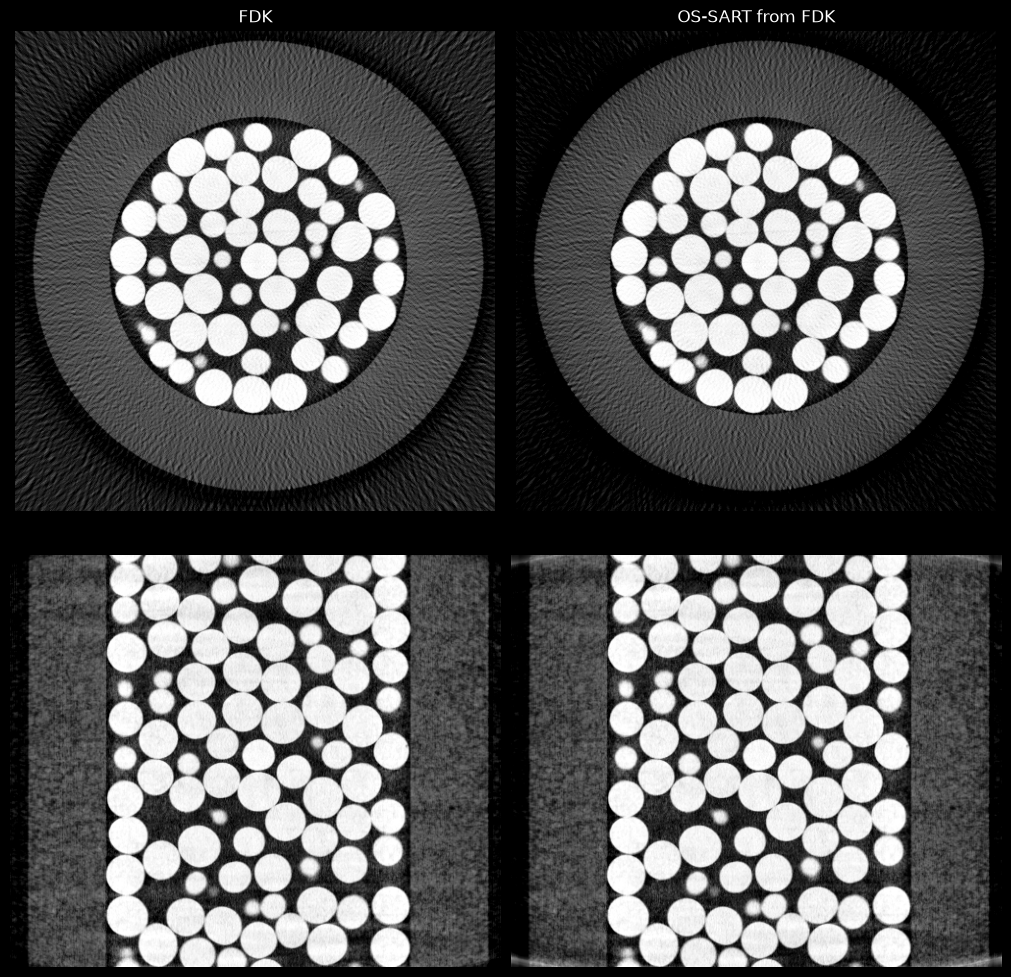

In [11]:
crop = slice(40, n - 40)  # slices away from the top and bottom of the cone
vmax = float(recon_fdk.max()) * 0.8
fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
fig.patch.set_facecolor('black')
for col, (recon, name) in enumerate([(recon_fdk, 'FDK'), (recon_sart, 'OS-SART from FDK')]):
    r = recon.cpu()
    axes[0, col].imshow(r[:, :, n // 2].T, cmap='Greys_r', vmin=0, vmax=vmax)
    axes[1, col].imshow(r[:, n // 2, crop].T, cmap='Greys_r', vmin=0, vmax=vmax)
    axes[0, col].set_title(name, color='white')
for ax in axes.flat:
    ax.axis('off')
plt.show()

In [12]:
air = (slice(0, 40), slice(0, 40), slice(n // 2 - 20, n // 2 + 20))  # a corner of the grid outside the tube
for recon, name in [(recon_fdk, 'FDK'), (recon_sart, 'OS-SART')]:
    a = recon[air]
    print(f"{name:8s} air: mean {float(a.mean()):+.4f} mm^-1, standard deviation {float(a.std()):.4f} mm^-1")

FDK      air: mean +0.0105 mm^-1, standard deviation 0.0065 mm^-1
OS-SART  air: mean +0.0015 mm^-1, standard deviation 0.0027 mm^-1


## Save the images

`io.save_dicom` writes the OS-SART image as a DICOM CT series, one file per slice (about 250 MB with `binning = 4`), where its grid's `object_meta` places it. It is attenuation per mm, not HU (`object_meta.units` is `'1/mm'`, which keeps its fractional values), and the sample has no patient frame, so the image is centred on the scanner's central ray.

In [13]:
saved = io.save_dicom(recon_sart, OUTPUT / 't_CT_microct' / 'os_sart', system_matrix.object_meta,
                      series_description='OS-SART 3x5 from FDK', overwrite=True)

## Next steps

- The same record has scans of this sample with 64 to 2,048 projections, made to compare reconstruction methods as the number of views falls. Change `256` in the folder and file names to try them.
- The [DICOM-CT-PD tutorial](t_CT_GEN3.ipynb) reconstructs a helical scan from a clinical scanner.

In [14]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 6.66, "peak_ram_gb": 13.1}
